# Lesson 15 - Fewer features: lower mel bands and whole feature groups

Lesson 13 used every mel band from 10 Hz to 16 kHz and all seven groups of engineered features. Two suggestions
to test here:

- **Remove the high-frequency bins** of the mel spectrogram (and so of the MFCCs), and use **fewer mel bands**
  than 128. Ship machinery sounds mostly at low frequencies; maybe the top of the spectrum adds only noise.
- **Swap whole sets of features**, not single numbers: do fewer groups, or a different combination, do as well?

The setup is exactly lesson 13's: the six classes, the same five folds and test ships, ship weights, logistic
regression and gradient boosting. Every choice (which version is "best") is made on the **validation** folds, and
only the **test** folds are reported, so the answers are not tuned to the test ships.

| Section | Question |
|---|---|
| 1. The mel bands | which frequencies each band covers, and how many bands survive each cut |
| 2. Cutting the top, merging bands | does the model need the high frequencies, and all 128 bands? |
| 3. Whole feature groups | which groups can go, and what is the smallest set that does as well? |
| 4. What it means | |

```
python src/six_classes_fewer.py features   # mel spectrogram -> data/features6_bands.parquet (about 4 minutes)
python src/six_classes_fewer.py bands      # section 2 -> runs/six_classes_fewer/bands_results.json (about 70 minutes)
python src/six_classes_fewer.py groups     # section 3 -> runs/six_classes_fewer/groups_*.{json,csv} (about 100 minutes)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import six_classes as S
import six_classes_fewer as B
from paths import DATA_DIR

OUT = B.OUT_DIR
COLORS = dict(zip(S.CLASSES6, ["#7f7f7f", "#2a78d6", "#1baf7a", "#eb6834", "#9b59b6", "#c0392b"]))
MODEL_COLORS = {"logistic regression": "#9ab8de", "gradient boosting": "#2a78d6"}
lesson13 = pd.DataFrame(json.loads((S.OUT_DIR / "results.json").read_text())["results"])
pd.set_option("display.width", 160)

## 1. The mel bands

The mel spectrogram of lesson 02 has 128 triangular bands, narrow at low frequencies and wide at high ones. Two
ways to use fewer of them:

- **Cut the top:** keep only the bands that lie entirely below a top frequency (8, 4, 2 or 1 kHz).
- **Merge neighbours:** add up the power of 2, 4 or 8 neighbouring bands, giving 64, 32 or 16 wider bands.

Both can be combined. Each version gives two feature sets: the **mean and spread of each band** over the 5 s
(lesson 13's simple set) and **MFCCs** computed from the kept bands only (coefficients 1-19, each with mean, spread
and how fast it changes; fewer when fewer than 20 bands are left).

In [2]:
counts = pd.DataFrame({f"merge {m}": [B.n_groups(t, m) for t in B.TOP_HZ] for m in B.MERGE},
                      index=[f"up to {t / 1000:.0f} kHz" for t in B.TOP_HZ])
print("bands kept:"); print(counts)
nfeat = pd.DataFrame({f"merge {m}": [f"{2 * B.n_groups(t, m)} / {3 * min(B.N_MFCC, B.n_groups(t, m) - 1)}"
                                     for t in B.TOP_HZ] for m in B.MERGE}, index=counts.index)
print("\nnumbers per clip (mean + spread of each band / MFCCs):"); print(nfeat)

bands kept:
              merge 1  merge 2  merge 4  merge 8
up to 16 kHz      128       64       32       16
up to 8 kHz       101       50       25       12
up to 4 kHz        76       38       19        9
up to 2 kHz        53       26       13        6
up to 1 kHz        34       17        8        4

numbers per clip (mean + spread of each band / MFCCs):
               merge 1   merge 2  merge 4  merge 8
up to 16 kHz  256 / 57  128 / 57  64 / 57  32 / 45
up to 8 kHz   202 / 57  100 / 57  50 / 57  24 / 33
up to 4 kHz   152 / 57   76 / 57  38 / 54  18 / 24
up to 2 kHz   106 / 57   52 / 57  26 / 36  12 / 15
up to 1 kHz    68 / 57   34 / 48  16 / 21    8 / 9


Where the class differences sit: the average level of each of the 128 bands, per class (fold-free: all clips),
with the four cuts marked.

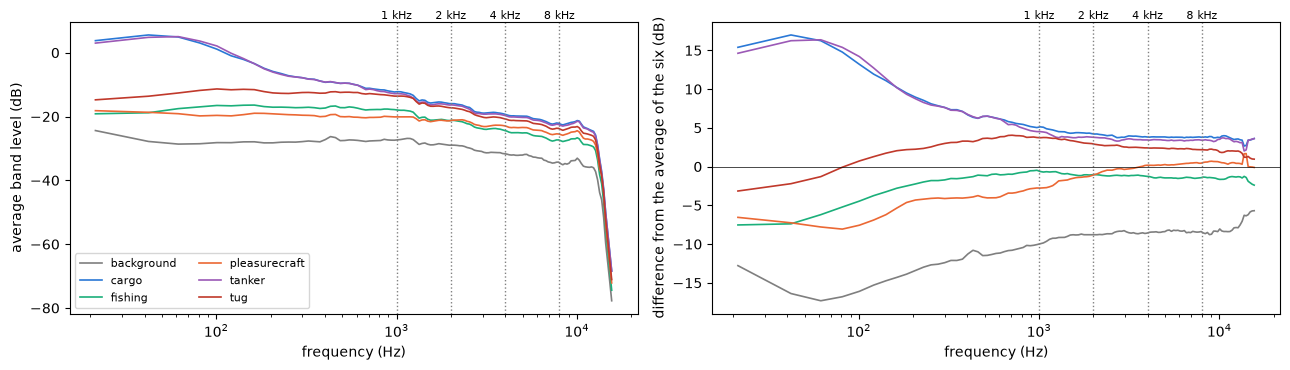

In [3]:
cols = [f"band1_{g}_mean" for g in range(128)]
bands = pd.read_parquet(DATA_DIR / B.BANDS_FILE, columns=["row", *cols]).set_index("row")
table = pd.read_parquet(DATA_DIR / "clips.parquet")
centre = np.array([np.sqrt(lo * hi) for lo, hi in B.group_edges(1)])
mean_db = bands.groupby(table.label.loc[bands.index].to_numpy()).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for c in S.CLASSES6:
    ax[0].semilogx(centre, mean_db.loc[c].to_numpy(), color=COLORS[c], lw=1.2, label=c)
    ax[1].semilogx(centre, mean_db.loc[c].to_numpy() - mean_db.mean().to_numpy(), color=COLORS[c], lw=1.2)
for a in ax:
    for t in B.TOP_HZ[1:]:
        a.axvline(t, color="grey", ls=":", lw=1)
        a.text(t, 1.0, f"{t / 1000:.0f} kHz", transform=a.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
    a.set_xlabel("frequency (Hz)")
ax[0].set_ylabel("average band level (dB)"); ax[0].legend(fontsize=8, ncol=2)
ax[1].set_ylabel("difference from the average of the six (dB)")
ax[1].axhline(0, color="black", lw=0.5)
plt.tight_layout(); plt.show()

**The biggest differences are below 1 kHz, but not all of them.**

- Cargo and tanker are 15-17 dB louder than the average below 200 Hz (big, slow engines and propellers), and their
  two curves lie on top of each other at every frequency. That is why the models confuse them.
- Above 1 kHz the curves run almost parallel, but they don't merge: the class averages still differ by 4-5 dB
  (8 dB below 1 kHz).
- The order of the small boats changes: pleasure craft is quieter than fishing boats below about 2 kHz and louder
  above. Only the high bands show that.
- All curves drop steeply above about 14 kHz. That is the anti-aliasing filter of the recording chain, not the
  ships.

## 2. Cutting the top and merging bands

Every version, both feature sets, both models, 5 test folds (balanced accuracy, chance 16.7 %). The top-left cell
of each map (16 kHz, 128 bands, mean and spread) is lesson 13's simple set (without its one overall-level number).

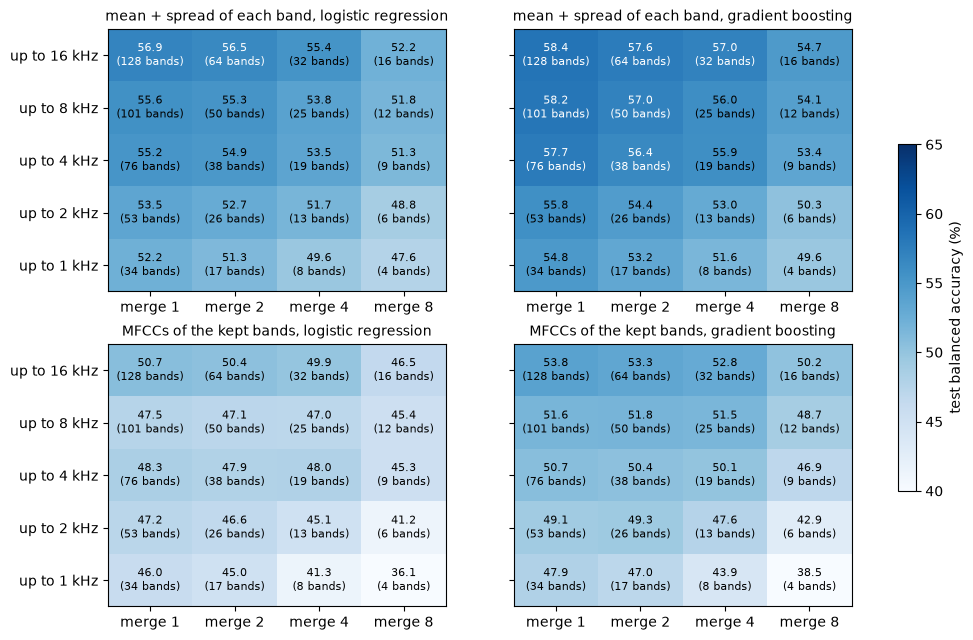

In [4]:
band_res = pd.DataFrame(json.loads((OUT / "bands_results.json").read_text())["results"])
grid = band_res.groupby(["kind", "model", "top_hz", "n_bands", "merge"]).agg(
    test=("balanced_accuracy", "mean"), spread=("balanced_accuracy", "std"),
    val=("val_balanced_accuracy", "mean"), n_features=("n_features", "first")).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for i, kind in enumerate(["bands", "mfcc"]):
    for j, model in enumerate(S.MODELS):
        g = grid[(grid.kind == kind) & (grid.model == model)].pivot(index="top_hz", columns="merge", values="test")
        g = g.sort_index(ascending=False)
        ax = axes[i, j]
        im = ax.imshow(100 * g.to_numpy(), cmap="Blues", vmin=40, vmax=65, aspect="auto")
        for a in range(g.shape[0]):
            for b in range(g.shape[1]):
                v = g.iloc[a, b]
                if np.isfinite(v):
                    ax.text(b, a, f"{100 * v:.1f}\n({B.n_groups(g.index[a], g.columns[b])} bands)", ha="center",
                            va="center", fontsize=8, color="white" if v > 0.56 else "black")
        ax.set_xticks(range(g.shape[1]), [f"merge {m}" for m in g.columns])
        ax.set_yticks(range(g.shape[0]), [f"up to {t / 1000:.0f} kHz" for t in g.index] if j == 0 else [])
        ax.set_title(f"{'mean + spread of each band' if kind == 'bands' else 'MFCCs of the kept bands'}, {model}",
                     fontsize=10)
fig.colorbar(im, ax=axes, label="test balanced accuracy (%)", shrink=0.6)
plt.show()

The same numbers as lines: first only the top cut (all bands below it kept), then only merging (up to 16 kHz).

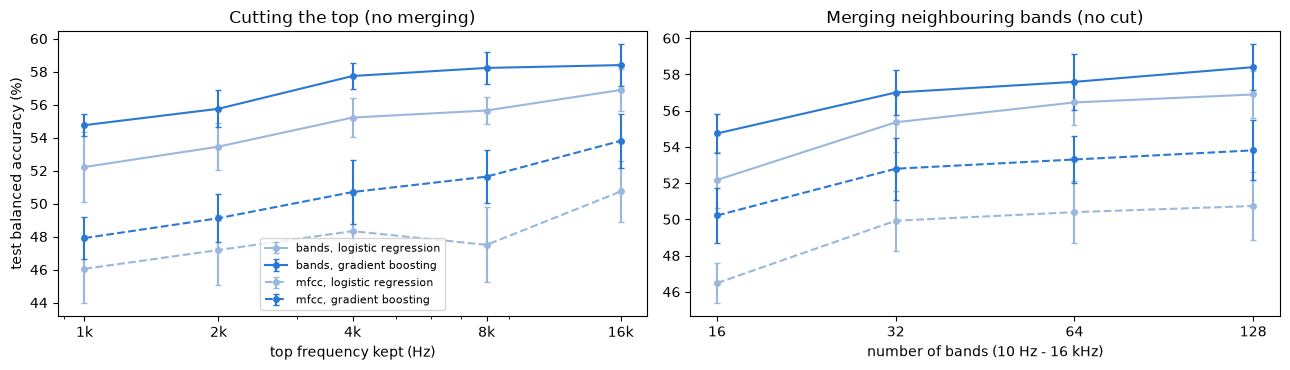

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for kind, ls in [("bands", "-"), ("mfcc", "--")]:
    for model in S.MODELS:
        g = grid[(grid["kind"] == kind) & (grid["model"] == model)]
        top = g[g["merge"] == 1].sort_values("top_hz")
        ax[0].errorbar(top["top_hz"], 100 * top["test"], yerr=100 * top["spread"], ls=ls, marker="o", ms=4,
                       capsize=2, color=MODEL_COLORS[model], label=f"{kind}, {model}")
        mer = g[g["top_hz"] == 16000].sort_values("n_bands")
        ax[1].errorbar(mer["n_bands"], 100 * mer["test"], yerr=100 * mer["spread"], ls=ls, marker="o", ms=4,
                       capsize=2, color=MODEL_COLORS[model])
ax[0].set_xscale("log"); ax[0].set_xticks(B.TOP_HZ, [f"{t / 1000:.0f}k" for t in B.TOP_HZ])
ax[0].set_xlabel("top frequency kept (Hz)"); ax[0].set_ylabel("test balanced accuracy (%)")
ax[0].set_title("Cutting the top (no merging)"); ax[0].legend(fontsize=8)
ax[1].set_xscale("log", base=2); ax[1].set_xticks([16, 32, 64, 128], ["16", "32", "64", "128"])
ax[1].set_xlabel("number of bands (10 Hz - 16 kHz)"); ax[1].set_title("Merging neighbouring bands (no cut)")
plt.tight_layout(); plt.show()

Which version would we pick **without looking at the test folds**? For each feature set and model: the version
with the fewest numbers whose mean validation score is within half a point of the best version (the rule of
lesson 13, section 5). Next to it, its test score and the full version's.

In [6]:
rows = []
for (kind, model), g in grid.groupby(["kind", "model"]):
    g = g.set_index(["top_hz", "merge"])
    pick = B.smallest_as_good(g["val"], g["n_features"])
    full = g.loc[(16000, 1)]
    rows.append({"features": kind, "model": model, "picked": f"up to {pick[0] / 1000:.0f} kHz, "
                 f"{B.n_groups(*pick)} bands", "numbers": int(g["n_features"][pick]),
                 "test (picked)": f"{100 * g['test'][pick]:.1f} ± {100 * g['spread'][pick]:.1f}",
                 "numbers (full)": int(full["n_features"]),
                 "test (full, 16 kHz, 128 bands)": f"{100 * full['test']:.1f} ± {100 * full['spread']:.1f}"})
picked = pd.DataFrame(rows).set_index(["features", "model"])
print(picked.to_string())

                                               picked  numbers test (picked)  numbers (full) test (full, 16 kHz, 128 bands)
features model                                                                                                             
bands    gradient boosting     up to 8 kHz, 101 bands      202    58.2 ± 1.0             256                     58.4 ± 1.3
         logistic regression   up to 16 kHz, 64 bands      128    56.5 ± 1.3             256                     56.9 ± 1.3
mfcc     gradient boosting    up to 16 kHz, 128 bands       57    53.8 ± 1.6              57                     53.8 ± 1.6
         logistic regression  up to 16 kHz, 128 bands       57    50.7 ± 1.9              57                     50.7 ± 1.9


**Removing the high frequencies doesn't help: on average every cut costs accuracy, just more or less.**

- **Mean and spread of the bands, gradient boosting:** up to 8 kHz 58.2 % (-0.2 points), 4 kHz 57.7 % (-0.7),
  2 kHz 55.8 % (-2.6), 1 kHz 54.8 % (-3.6), against 58.4 % with everything. Logistic regression loses more at every
  cut (-1.3 points at 8 kHz, -4.7 at 1 kHz). Per ship, gradient boosting up to 4-8 kHz is level with the full set
  (67.0 and 66.7 against 66.5 %).
- **MFCCs suffer most:** cutting at 8 kHz already costs 2.2 points (gradient boosting) and 3.2 (logistic
  regression), at 1 kHz 4.7-5.9 points. MFCCs describe the shape of the whole spectrum; without the top they lose the
  balance between low and high frequencies.
- **Merging bands costs less than cutting:** 64 bands (half the numbers) cost 0.4-0.8 points, 32 bands 1.4-1.5,
  16 bands 3.7-4.7.
- **Picked on validation:** gradient boosting on the bands up to 8 kHz (202 numbers instead of 256; 58.2 against
  58.4 %), logistic regression on 64 bands up to 16 kHz (128 numbers instead of 256; 56.5 against 56.9 %), and for
  MFCCs the full version. So a fifth to a half of the band numbers can go for less than half a point, but **no
  version beats the full one.**
- On their own, the MFCCs of this lesson (from the finer 128-band spectrogram) score 53.8 % with gradient boosting
  and 50.7 % with logistic regression: 1.4 and 3.5 points more than lesson 13's MFCCs from 40 bands (52.4 and
  47.2 %, lesson 13 section 7).

## 3. Whole feature groups

Lesson 13's 144 engineered numbers come in seven groups. Two experiments, each with whole groups only:

- **Leave one out:** train with six of the seven groups; how much does the test score drop without each one?
- **Add one at a time:** start with nothing; at each step add the group that raises the mean **validation**
  score most. This gives the best set of 1, 2, ..., 7 groups and shows where adding more stops helping.

numbers per group: {'MFCC': 57, '1/3-octave levels': 29, 'level changes over time': 9, 'spectral shape': 28, 'loudness and impulsiveness': 5, 'tonal lines': 5, 'propeller modulation (DEMON)': 11}

all seven groups (test): {'gradient boosting': 61.9, 'logistic regression': 60.8}

change in test balanced accuracy (points) when one group is left out:
model                         gradient boosting  logistic regression
left_out                                                            
propeller modulation (DEMON)               -1.1                 -1.2
1/3-octave levels                          -1.0                 -0.9
level changes over time                    -0.6                 -0.4
MFCC                                       -0.4                 -1.2
tonal lines                                -0.3                 -0.3
spectral shape                             -0.1                 -0.7
loudness and impulsiveness                  0.2                  0.2


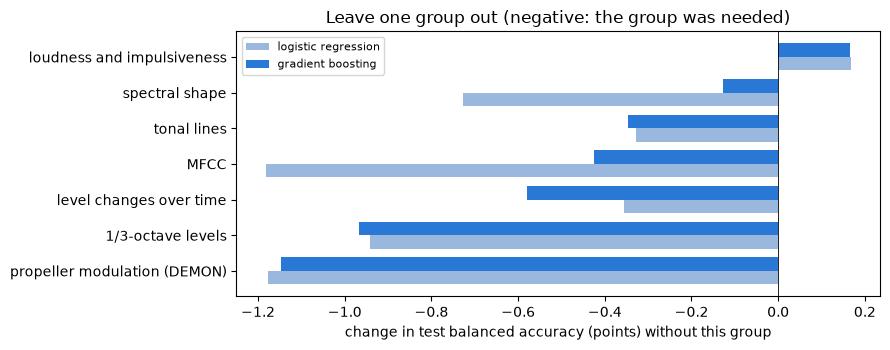

In [7]:
grp = json.loads((OUT / "groups_results.json").read_text())
gres = pd.DataFrame(grp["results"])
print("numbers per group:", grp["groups"])

logo = gres[gres.kind == "leave one out"]
base = logo[logo.left_out == "(none)"].groupby("model").balanced_accuracy.mean()
drop = logo[logo.left_out != "(none)"].groupby(["left_out", "model"]).balanced_accuracy.agg(["mean", "std"])
drop["change"] = drop["mean"] - base.reindex(drop.index.get_level_values("model")).to_numpy()
change = (100 * drop.change).unstack("model").sort_values("gradient boosting")
print("\nall seven groups (test):", (100 * base).round(1).to_dict())
print("\nchange in test balanced accuracy (points) when one group is left out:")
print(change.round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(change))
for k, model in enumerate(S.MODELS):
    ax.barh(y + (k - 0.5) * 0.38, change[model], 0.38, color=MODEL_COLORS[model], label=model)
ax.set_yticks(y, change.index); ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("change in test balanced accuracy (points) without this group"); ax.legend(fontsize=8)
ax.set_title("Leave one group out (negative: the group was needed)"); plt.tight_layout(); plt.show()

Adding one group at a time (chosen on the validation folds):

                                                 added  n_features   val  test  spread
model               step                                                              
gradient boosting   1                1/3-octave levels          29  54.3  54.5     1.0
                    2                             MFCC          86  57.5  58.6     1.0
                    3     propeller modulation (DEMON)          97  59.7  60.4     1.2
                    4          level changes over time         106  60.7  61.3     1.2
                    5                      tonal lines         111  61.1  61.5     1.1
                    6       loudness and impulsiveness         116  61.1  61.7     1.0
                    7                   spectral shape         144  60.7  61.9     1.1
logistic regression 1                1/3-octave levels          29  54.3  54.2     1.2
                    2     propeller modulation (DEMON)          40  56.6  56.8     1.7
                    3                   spe

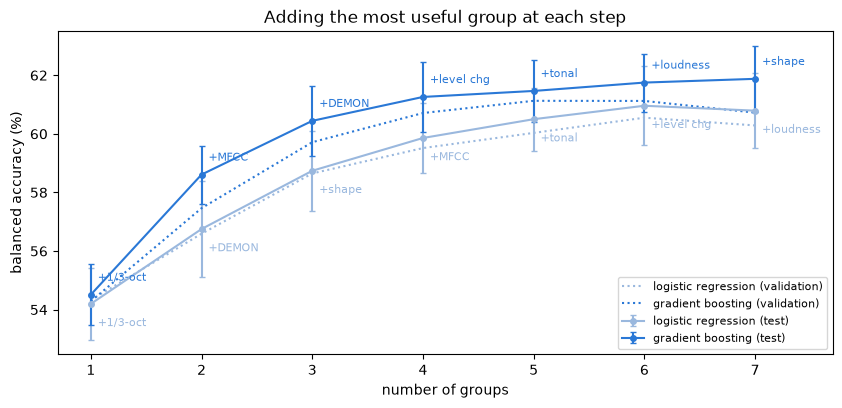

In [8]:
fwd = gres[gres.kind == "forward"].astype({"step": int})
path = fwd.groupby(["model", "step"]).agg(added=("added", "first"), n_features=("n_features", "first"),
                                          val=("val_balanced_accuracy", "mean"),
                                          test=("balanced_accuracy", "mean"), spread=("balanced_accuracy", "std"))
show = path.assign(val=(100 * path.val).round(1), test=(100 * path.test).round(1),
                   spread=(100 * path.spread).round(1))
print(show.to_string())

SHORT = {"MFCC": "MFCC", "1/3-octave levels": "1/3-oct", "level changes over time": "level chg",
         "spectral shape": "shape", "loudness and impulsiveness": "loudness", "tonal lines": "tonal",
         "propeller modulation (DEMON)": "DEMON"}
fig, ax = plt.subplots(figsize=(10, 4.2))
for model, dy in zip(S.MODELS, (-16, 10)):
    p = path.loc[model]
    ax.errorbar(p.index, 100 * p.test, yerr=100 * p.spread, marker="o", ms=4, capsize=2, color=MODEL_COLORS[model],
                label=f"{model} (test)")
    ax.plot(p.index, 100 * p.val, ls=":", color=MODEL_COLORS[model], label=f"{model} (validation)")
    for s, row in p.iterrows():
        ax.annotate(f"+{SHORT[row.added]}", (s, 100 * row.test), textcoords="offset points", xytext=(5, dy),
                    fontsize=8, color=MODEL_COLORS[model])
ax.set_xlim(0.7, 7.7); ax.set_xlabel("number of groups"); ax.set_ylabel("balanced accuracy (%)")
ax.set_title("Adding the most useful group at each step"); ax.legend(fontsize=8); plt.show()

Every candidate at every step (mean validation score, %; blank once the group is in). Close numbers in a column
mean that those groups could replace each other at that step.

In [9]:
cand = pd.read_csv(OUT / "groups_forward.csv")
for model in S.MODELS:
    t = cand[cand.model == model].pivot(index="candidate", columns="step", values="val_balanced_accuracy")
    print(f"\n{model}:")
    print((100 * t).round(1).astype(object).where(t.notna(), "").to_string())

rows = []
for model in S.MODELS:
    p = path.loc[model]
    pick = B.smallest_as_good(p["val"], p["n_features"])
    chosen = fwd[(fwd["model"] == model) & (fwd["step"] == pick)]["groups"].iloc[0]
    rows.append({"model": model, "groups": ", ".join(chosen), "numbers": int(p["n_features"][pick]),
                 "test (picked)": f"{100 * p['test'][pick]:.1f} ± {100 * p['spread'][pick]:.1f}",
                 "test (all seven, 144)": f"{100 * p['test'][7]:.1f} ± {100 * p['spread'][7]:.1f}"})
print(pd.DataFrame(rows).set_index("model").T.to_string())


logistic regression:
step                             1     2     3     4     5     6
candidate                                                       
1/3-octave levels             54.3                              
MFCC                          47.0  56.6  58.3  59.5            
level changes over time       30.8  55.8  58.0  59.0  59.9  60.6
loudness and impulsiveness    49.0  54.5  57.0  58.6  59.4  60.0
propeller modulation (DEMON)  36.8  56.6                        
spectral shape                51.4  56.3  58.6                  
tonal lines                   33.9  55.5  57.5  58.9  60.0      

gradient boosting:
step                             1     2     3     4     5     6
candidate                                                       
1/3-octave levels             54.3                              
MFCC                          51.7  57.5                        
level changes over time       37.6  56.7  58.5  60.7            
loudness and impulsiveness    48.6  54.4  57.6  

**Every group adds a little, no single group is essential, and one can go.**

- **Leave one out:** no group costs more than 1.2 points when it is left out. The groups overlap: MFCCs, the
  1/3-octave levels and the spectral shape all describe the same spectrum in different ways. The most missed are
  propeller modulation (DEMON, -1.1 / -1.2 points) and the 1/3-octave levels (-1.0 / -0.9); for logistic
  regression also the MFCCs (-1.2).
- **Loudness and impulsiveness (5 numbers) can go:** both models score 0.2 points higher without it
  (gradient boosting 62.0 %, logistic regression 61.0 %). For gradient boosting, the spectral shape (28 numbers)
  costs only 0.1 points.
- **Adding one at a time:** the 1/3-octave levels are the best single group for both models: 29 numbers give
  54.2-54.5 %. After that the models differ. At step 2, MFCC and DEMON are almost tied on validation for both
  models (57.5 against 57.4 % and 56.6 against 56.6 %), so either can be the second group.
- **Smallest set as good as all seven** (within half a point on validation): gradient boosting needs 4 groups,
  106 numbers (1/3-octave levels, MFCC, DEMON, level changes): 61.3 % against 61.9 % (0.4-0.8 points lower on
  every fold). Logistic regression needs 6 groups, 139 numbers (all but loudness and impulsiveness): 61.0 against
  60.8 %.
- **Three groups already beat the 256 band numbers:** gradient boosting with 1/3-octave levels + MFCC + DEMON
  (97 numbers) 60.4 % against 58.4 %; logistic regression with 1/3-octave levels + DEMON + spectral shape
  (68 numbers) 58.7 % against 56.9 %.

## 4. What it means

| Test balanced accuracy, same test ships | Numbers | Gradient boosting | Logistic regression |
|---|---|---|---|
| mel bands, all 128, up to 16 kHz (lesson 13's simple set) | 256 | 58.4 % | 56.9 % |
| mel bands up to 8 kHz | 202 | 58.2 % | 55.6 % |
| 64 mel bands up to 16 kHz | 128 | 57.6 % | 56.5 % |
| mel bands up to 1 kHz | 68 | 54.8 % | 52.2 % |
| engineered, all seven groups (lesson 13) | 144 | **61.9 %** | 60.8 % |
| engineered without loudness and impulsiveness | 139 | **62.0 %** | **61.0 %** |
| engineered, best 4 groups for gradient boosting | 106 | 61.3 % | |
| engineered, best 3 groups | 68-97 | 60.4 % | 58.7 % |

- **Removing the high frequencies doesn't improve the result on this data.** Up to 14 kHz the ship classes stay
  6-12 dB above the background on average (section 1), and they still differ from each other there. On average, cutting at 8 kHz costs
  0.2-1.3 points, at 1 kHz 3.6-4.7 points, and MFCCs lose more (2-3 points already at 8 kHz).
- **Fewer bands cost little down to 64:** half the band numbers for 0.4-0.8 points; 32 bands cost 1.5 and
  16 bands 3.7-4.7 points.
- **Fewer numbers, about the same result, is possible:** bands up to 8 kHz for gradient boosting (-0.2), 64 bands
  for logistic regression (-0.4), and the engineered set without loudness and impulsiveness (+0.2, within the
  fold spread of about 1 point). **Better is not:** none of the versions or group sets tried beats the full set by
  more than 0.2 points.
- **What matters is the kind of feature, not how many:** 97 engineered numbers (three groups) beat 256 mel-band
  numbers by 2 points. The 1/3-octave levels and DEMON carry the most that the others don't.
- **Recommendation:** keep the full 128 bands up to 16 kHz; for the engineered set, either keep all seven groups
  or drop loudness and impulsiveness. The difference is too small to matter.